In [74]:
#Feature Engineering Techniques with Python
#Data compatible with the machine learning algorithm
#Machine learning algorithms sometimes expect data formatted in a certain way
#Data preprocessing
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [75]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [76]:
# loading dataset
dataset = pd.read_csv(r'/content/ai_jobs_salaries_clean.csv')
print(dataset, "\n")

       work_year experience_level employment_type                 job_title  \
0           2025               EX              FT              Head of Data   
1           2025               EX              FT              Head of Data   
2           2025               SE              FT            Data Scientist   
3           2025               SE              FT            Data Scientist   
4           2025               MI              FT                  Engineer   
...          ...              ...             ...                       ...   
71908       2020               SE              FT            Data Scientist   
71909       2021               MI              FT  Principal Data Scientist   
71910       2020               EN              FT            Data Scientist   
71911       2020               EN              CT     Business Data Analyst   
71912       2021               SE              FT            Data Scientist   

        salary salary_currency  salary_in_usd emplo

In [77]:
# Inspect the dataset's columns and data types
print(dataset.info())
display(dataset.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71913 entries, 0 to 71912
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   work_year               71913 non-null  int64 
 1   experience_level        71913 non-null  object
 2   employment_type         71913 non-null  object
 3   job_title               71913 non-null  object
 4   salary                  71913 non-null  int64 
 5   salary_currency         71913 non-null  object
 6   salary_in_usd           71913 non-null  int64 
 7   employee_residence      71913 non-null  object
 8   remote_ratio            71913 non-null  int64 
 9   company_location        71913 non-null  object
 10  company_size            71913 non-null  object
 11  experience_level_label  71913 non-null  object
 12  employment_type_label   71913 non-null  object
 13  work_mode               71913 non-null  object
 14  salary_outlier_flag     71913 non-null  bool  
 15  ro

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN


In [78]:
# ai_company_adoption Dataset
# We will use the already loaded 'dataset' variables to apply our feature engineering techniques.
print(dataset.info())
print(dataset.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71913 entries, 0 to 71912
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   work_year               71913 non-null  int64 
 1   experience_level        71913 non-null  object
 2   employment_type         71913 non-null  object
 3   job_title               71913 non-null  object
 4   salary                  71913 non-null  int64 
 5   salary_currency         71913 non-null  object
 6   salary_in_usd           71913 non-null  int64 
 7   employee_residence      71913 non-null  object
 8   remote_ratio            71913 non-null  int64 
 9   company_location        71913 non-null  object
 10  company_size            71913 non-null  object
 11  experience_level_label  71913 non-null  object
 12  employment_type_label   71913 non-null  object
 13  work_mode               71913 non-null  object
 14  salary_outlier_flag     71913 non-null  bool  
 15  ro

In [79]:
dataset.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN


In [80]:
############################Imputation#####################################
#Imputation : the assignment of a value to something by inference (Simple value, Mean, Max, Min feature value)
#detect missing data
print(dataset.isnull().sum())


work_year                     0
experience_level              0
employment_type               0
job_title                     0
salary                        0
salary_currency               0
salary_in_usd                 0
employee_residence            0
remote_ratio                  0
company_location              0
company_size                  0
experience_level_label        0
employment_type_label         0
work_mode                     0
salary_outlier_flag           0
role_family                   0
isco_group_hint           40540
dtype: int64


In [81]:
#The easiest deal with missing values is to drop samples with missing values from the dataset: Not optimal
dataset = dataset.dropna()
dataset.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
8,2025,SE,FT,AI Engineer,97900,USD,97900,US,100,US,M,Senior-level,Full-time,Remote,False,AI Engineer,Software and applications developers


In [82]:
#replace missing values, categorical features?
dataset = dataset.fillna(99)

In [83]:
dataset.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
8,2025,SE,FT,AI Engineer,97900,USD,97900,US,100,US,M,Senior-level,Full-time,Remote,False,AI Engineer,Software and applications developers


In [84]:
# Imputation: Let's identify columns with missing values in our active dataset and impute them.
# We will use 'annual_revenue_usd' or similar numeric columns for mean imputation.
numeric_cols = dataset.select_dtypes(include=[np.number]).columns
if len(numeric_cols) > 0:
    target_col = numeric_cols[0]
    dataset[target_col].fillna((dataset[target_col].mean()), inplace=True)
    print(f"Imputed missing values in '{target_col}' with its mean: {dataset[target_col].mean()}")
dataset.head()

/tmp/ipykernel_371/2275074560.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset[target_col].fillna((dataset[target_col].mean()), inplace=True)


Imputed missing values in 'work_year' with its mean: 2024.2235361616677


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
8,2025,SE,FT,AI Engineer,97900,USD,97900,US,100,US,M,Senior-level,Full-time,Remote,False,AI Engineer,Software and applications developers


In [85]:
dataset.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
8,2025,SE,FT,AI Engineer,97900,USD,97900,US,100,US,M,Senior-level,Full-time,Remote,False,AI Engineer,Software and applications developers


In [86]:
# Impute other numeric and categorical columns dynamically
for col in dataset.select_dtypes(include=[np.number]).columns:
    dataset[col].fillna(dataset[col].mean(), inplace=True)

# Impute categorical variables with the most frequent value
for col in dataset.select_dtypes(include=['object', 'category']).columns:
    if dataset[col].isnull().any():
        dataset[col].fillna(dataset[col].mode()[0], inplace=True)

dataset.reset_index(drop=True, inplace=True)
dataset.head()

/tmp/ipykernel_371/3856227539.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset[col].fillna(dataset[col].mean(), inplace=True)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,SE,FT,AI Engineer,97900,USD,97900,US,100,US,M,Senior-level,Full-time,Remote,False,AI Engineer,Software and applications developers


In [87]:
# Make sure we read the active dataset without overriding with the missing penguins file
dataset = pd.read_csv('/content/ai_jobs_salaries_clean.csv')
print("Dataset loaded successfully. Shape:", dataset.shape)

Dataset loaded successfully. Shape: (71913, 17)


In [88]:
print(dataset.isnull().sum())


work_year                     0
experience_level              0
employment_type               0
job_title                     0
salary                        0
salary_currency               0
salary_in_usd                 0
employee_residence            0
remote_ratio                  0
company_location              0
company_size                  0
experience_level_label        0
employment_type_label         0
work_mode                     0
salary_outlier_flag           0
role_family                   0
isco_group_hint           40540
dtype: int64


In [89]:
# Check for null/invalid values in a categorical feature like 'country'
print("Unique countries:", dataset['country'].unique() if 'country' in dataset.columns else 'N/A')

Unique countries: N/A


In [90]:
# Drop rows with critical missing categorical variables if necessary
dataset = dataset.dropna(subset=['country']) if 'country' in dataset.columns else dataset
dataset.reset_index(drop=True, inplace=True)

In [91]:
###########################Categorical Encoding#####################################
#Categorical Encoding
#Discrete values and represent some sort of category or class
#Direct support to categorical variables without further manipulation, but some ML Algorithms does not support
dataset.dtypes

,0
work_year,int64
experience_level,object
employment_type,object
job_title,object
salary,int64
salary_currency,object
salary_in_usd,int64
employee_residence,object
remote_ratio,int64
company_location,object


In [92]:
# Convert categorical columns to 'category' type
cat_cols = ['country', 'quarter', 'sector']
for col in cat_cols:
    if col in dataset.columns:
        dataset[col] = dataset[col].astype('category')
print(dataset.dtypes)

work_year                  int64
experience_level          object
employment_type           object
job_title                 object
salary                     int64
salary_currency           object
salary_in_usd              int64
employee_residence        object
remote_ratio               int64
company_location          object
company_size              object
experience_level_label    object
employment_type_label     object
work_mode                 object
salary_outlier_flag         bool
role_family               object
isco_group_hint           object
dtype: object


In [93]:
# Extract categorical features
categorical_data = dataset.select_dtypes(include=['category', 'object']).copy()
categorical_data.head()

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,experience_level_label,employment_type_label,work_mode,role_family,isco_group_hint
0,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...
1,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...
2,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians"
3,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians"
4,MI,FT,Engineer,USD,US,US,M,Mid-level,Full-time,Remote,Other / Unclassified,NaN


In [94]:
# Categorical Encoding: Label Encoding using .cat.codes
for col in categorical_data.select_dtypes(include=['category']).columns:
    categorical_data[f"{col}_cat"] = categorical_data[col].cat.codes
categorical_data.head()

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,experience_level_label,employment_type_label,work_mode,role_family,isco_group_hint
0,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...
1,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...
2,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians"
3,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians"
4,MI,FT,Engineer,USD,US,US,M,Mid-level,Full-time,Remote,Other / Unclassified,NaN


In [95]:
print(categorical_data)


      experience_level employment_type                 job_title  \
0                   EX              FT              Head of Data   
1                   EX              FT              Head of Data   
2                   SE              FT            Data Scientist   
3                   SE              FT            Data Scientist   
4                   MI              FT                  Engineer   
...                ...             ...                       ...   
71908               SE              FT            Data Scientist   
71909               MI              FT  Principal Data Scientist   
71910               EN              FT            Data Scientist   
71911               EN              CT     Business Data Analyst   
71912               SE              FT            Data Scientist   

      salary_currency employee_residence company_location company_size  \
0                 USD                 US               US            M   
1                 USD              

In [96]:
# Categorical Encoding: One-Hot Encoding on experience_level
if 'experience_level' in categorical_data.columns:
    encoded_experience = pd.get_dummies(categorical_data['experience_level'], prefix='exp')
else:
    encoded_experience = pd.DataFrame()
encoded_experience.head()

,exp_EN,exp_EX,exp_MI,exp_SE
0,False,True,False,False
1,False,True,False,False
2,False,False,False,True
3,False,False,False,True
4,False,False,True,False


In [97]:
# Join the encoded features avoiding index conflicts by using pd.concat
import pandas as pd
if not encoded_country.empty:
    categorical_data = pd.concat([categorical_data, encoded_country], axis=1)
categorical_data.head()

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,experience_level_label,employment_type_label,work_mode,role_family,isco_group_hint
0,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...
1,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...
2,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians"
3,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians"
4,MI,FT,Engineer,USD,US,US,M,Mid-level,Full-time,Remote,Other / Unclassified,NaN


In [98]:
print(categorical_data)

      experience_level employment_type                 job_title  \
0                   EX              FT              Head of Data   
1                   EX              FT              Head of Data   
2                   SE              FT            Data Scientist   
3                   SE              FT            Data Scientist   
4                   MI              FT                  Engineer   
...                ...             ...                       ...   
71908               SE              FT            Data Scientist   
71909               MI              FT  Principal Data Scientist   
71910               EN              FT            Data Scientist   
71911               EN              CT     Business Data Analyst   
71912               SE              FT            Data Scientist   

      salary_currency employee_residence company_location company_size  \
0                 USD                 US               US            M   
1                 USD              

In [99]:
# Perform One-Hot Encoding on other categorical fields like company_size if it exists
if 'company_size' in categorical_data.columns:
    encoded_size = pd.get_dummies(categorical_data['company_size'], prefix='size')
    categorical_data = pd.concat([categorical_data, encoded_size], axis=1)
categorical_data.head()

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,experience_level_label,employment_type_label,work_mode,role_family,isco_group_hint,size_L,size_M,size_S
0,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...,False,True,False
1,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...,False,True,False
2,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians",False,True,False
3,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians",False,True,False
4,MI,FT,Engineer,USD,US,US,M,Mid-level,Full-time,Remote,Other / Unclassified,NaN,False,True,False


In [100]:
# Load the correct dataset path
dataset = pd.read_csv('/content/ai_jobs_salaries_clean.csv')
print("Active dataset loaded.")

Active dataset loaded.


In [101]:
# Set proper categories based on columns that exist in the active dataset
for col in ['experience_level', 'employment_type', 'company_size', 'work_mode']:
    if col in dataset.columns:
        dataset[col] = dataset[col].astype('category')
dataset.dtypes

,0
work_year,int64
experience_level,category
employment_type,category
job_title,object
salary,int64
salary_currency,object
salary_in_usd,int64
employee_residence,object
remote_ratio,int64
company_location,object


In [102]:
# Isolate categorical columns
categorical_data = dataset.select_dtypes(include=['category', 'object']).copy()
categorical_data.head()

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,experience_level_label,employment_type_label,work_mode,role_family,isco_group_hint
0,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...
1,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,Analytics Manager,Information and communications technology serv...
2,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians"
3,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Data Scientist,"Mathematicians, actuaries and statisticians"
4,MI,FT,Engineer,USD,US,US,M,Mid-level,Full-time,Remote,Other / Unclassified,NaN


In [103]:
# Joint encoded features if they exist
print(categorical_data.columns)

Index(['experience_level', 'employment_type', 'job_title', 'salary_currency',
       'employee_residence', 'company_location', 'company_size',
       'experience_level_label', 'employment_type_label', 'work_mode',
       'role_family', 'isco_group_hint'],
      dtype='object')


In [104]:
print(categorical_data)

      experience_level employment_type                 job_title  \
0                   EX              FT              Head of Data   
1                   EX              FT              Head of Data   
2                   SE              FT            Data Scientist   
3                   SE              FT            Data Scientist   
4                   MI              FT                  Engineer   
...                ...             ...                       ...   
71908               SE              FT            Data Scientist   
71909               MI              FT  Principal Data Scientist   
71910               EN              FT            Data Scientist   
71911               EN              CT     Business Data Analyst   
71912               SE              FT            Data Scientist   

      salary_currency employee_residence company_location company_size  \
0                 USD                 US               US            M   
1                 USD              

In [105]:
# Visualise categorical data properties
print(categorical_data.head())

  experience_level employment_type       job_title salary_currency  \
0               EX              FT    Head of Data             USD   
1               EX              FT    Head of Data             USD   
2               SE              FT  Data Scientist             USD   
3               SE              FT  Data Scientist             USD   
4               MI              FT        Engineer             USD   

  employee_residence company_location company_size experience_level_label  \
0                 US               US            M        Executive-level   
1                 US               US            M        Executive-level   
2                 US               US            M           Senior-level   
3                 US               US            M           Senior-level   
4                 US               US            M              Mid-level   

  employment_type_label work_mode           role_family  \
0             Full-time   On-site     Analytics Manager  

In [106]:
# Count Encoding for categorical columns
dataset = pd.read_csv('/content/ai_jobs_salaries_clean.csv')
categorical_data = dataset.select_dtypes(include=['object']).copy()
print(categorical_data.head())

  experience_level employment_type       job_title salary_currency  \
0               EX              FT    Head of Data             USD   
1               EX              FT    Head of Data             USD   
2               SE              FT  Data Scientist             USD   
3               SE              FT  Data Scientist             USD   
4               MI              FT        Engineer             USD   

  employee_residence company_location company_size experience_level_label  \
0                 US               US            M        Executive-level   
1                 US               US            M        Executive-level   
2                 US               US            M           Senior-level   
3                 US               US            M           Senior-level   
4                 US               US            M              Mid-level   

  employment_type_label work_mode           role_family  \
0             Full-time   On-site     Analytics Manager  

In [107]:
# Dynamically drop numeric columns of the active dataset to keep only categorical ones
categorical_data = dataset.select_dtypes(exclude=[np.number]).copy()
categorical_data.head()

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,MI,FT,Engineer,USD,US,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN


In [108]:
# Calculate frequencies
counts_dict = {}
for col in categorical_data.columns:
    counts_dict[col] = categorical_data[col].value_counts()

In [109]:
# Map values to their frequency counts
for col in categorical_data.columns:
    categorical_data[f'{col}_count_enc'] = categorical_data[col].map(counts_dict[col])
categorical_data.head()

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,experience_level_label,employment_type_label,work_mode,...,salary_currency_count_enc,employee_residence_count_enc,company_location_count_enc,company_size_count_enc,experience_level_label_count_enc,employment_type_label_count_enc,work_mode_count_enc,salary_outlier_flag_count_enc,role_family_count_enc,isco_group_hint_count_enc
0,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,...,65910,60085,60147,70110,2841,71163,54081,1754,495,495.0
1,EX,FT,Head of Data,USD,US,US,M,Executive-level,Full-time,On-site,...,65910,60085,60147,70110,2841,71163,54081,70159,495,495.0
2,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,...,65910,60085,60147,70110,37702,71163,54081,70159,7216,7216.0
3,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,...,65910,60085,60147,70110,37702,71163,54081,70159,7216,7216.0
4,MI,FT,Engineer,USD,US,US,M,Mid-level,Full-time,Remote,...,65910,60085,60147,70110,23395,71163,17505,70159,40540,NaN


In [110]:
#Categorical Encoding:Target Encoding and Leave One Out Target Encoding ?

In [111]:
##########################Handling Outliers######################################

In [112]:
#Outliers: are values that are deviating from the whole distribution of the data.

In [113]:
#Inter-quartile range :IQR indicates where 50 percent of data is located
import seaborn as sb

In [114]:
# Load the active dataset for visualizing outliers
dataset = pd.read_csv('/content/ai_jobs_salaries_clean.csv')

/tmp/ipykernel_371/3664939979.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=dataset, y=col, ax=axes[i], palette="Oranges")
/tmp/ipykernel_371/3664939979.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=dataset, y=col, ax=axes[i], palette="Oranges")
/tmp/ipykernel_371/3664939979.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=dataset, y=col, ax=axes[i], palette="Oranges")
/tmp/ipykernel_371/3664939979.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign 

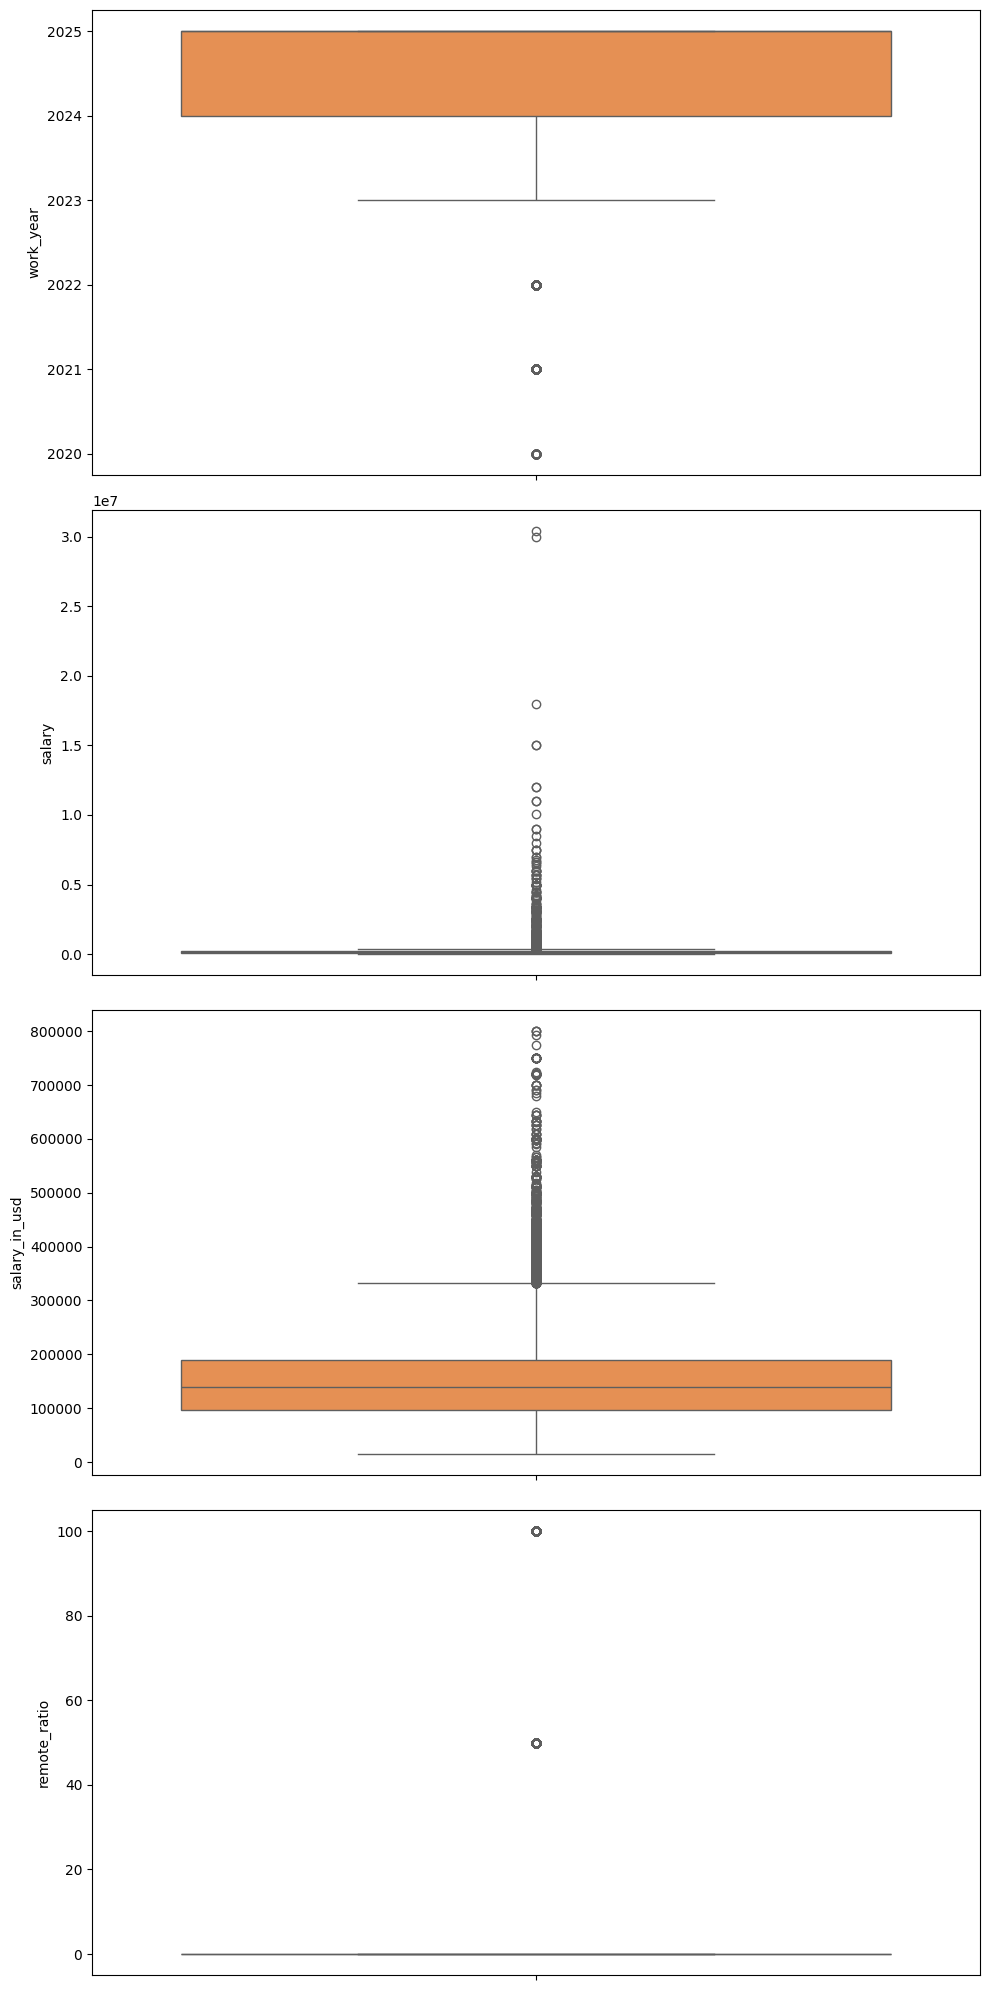

In [115]:
# Outlier analysis using boxplots on numeric columns of the dataset
numeric_cols = dataset.select_dtypes(include=[np.number]).columns[:4]
fig, axes = plt.subplots(nrows=len(numeric_cols), ncols=1, figsize=(10, 5 * len(numeric_cols)))
import seaborn as sb
for i, col in enumerate(numeric_cols):
    sb.boxplot(data=dataset, y=col, ax=axes[i], palette="Oranges")
plt.tight_layout()
plt.show()

/tmp/ipykernel_371/3046562935.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(x=top_locations.values, y=top_locations.index, ax=axes[1], palette='viridis')


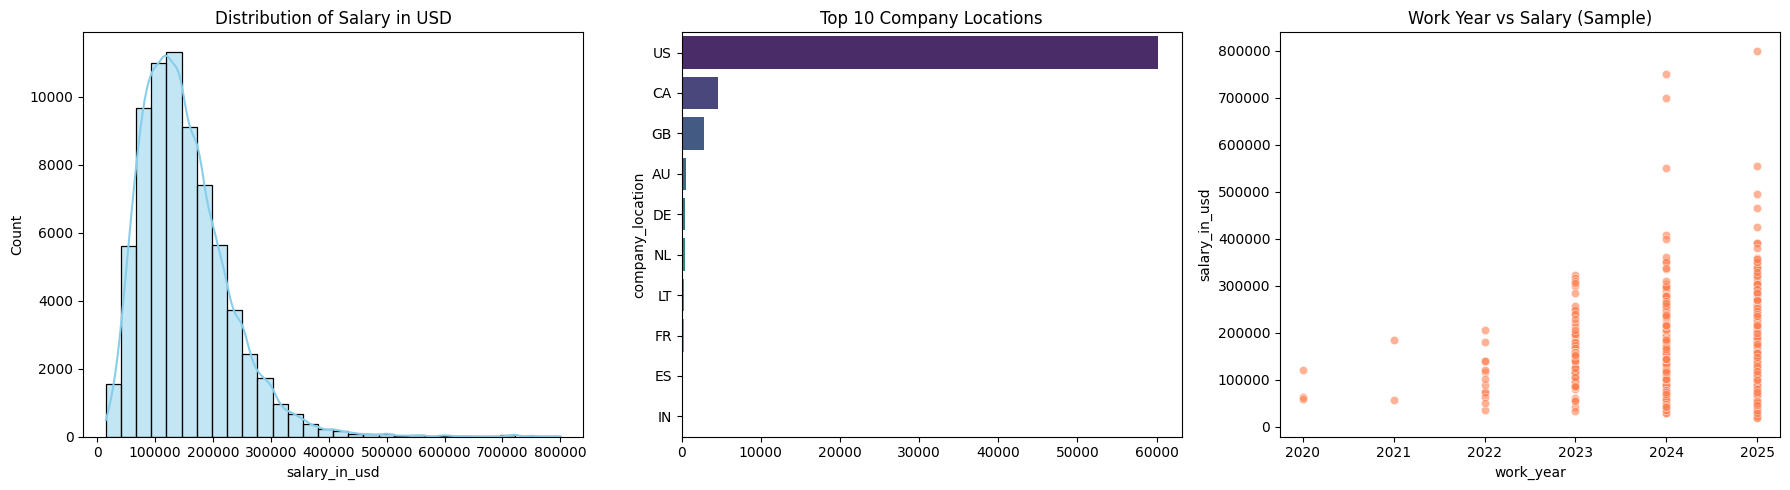

In [116]:
# Add different types of graphs to display data characteristics
import matplotlib.pyplot as plt
import seaborn as sb

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# 1. Histogram of salary
sb.histplot(data=dataset, x='salary_in_usd', bins=30, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('Distribution of Salary in USD')

# 2. Bar plot of Top 10 Company Locations
top_locations = dataset['company_location'].value_counts().head(10)
sb.barplot(x=top_locations.values, y=top_locations.index, ax=axes[1], palette='viridis')
axes[1].set_title('Top 10 Company Locations')

# 3. Scatter plot of Work Year vs Salary
sb.scatterplot(data=dataset.sample(1000, random_state=42), x='work_year', y='salary_in_usd', ax=axes[2], alpha=0.6, color='coral')
axes[2].set_title('Work Year vs Salary (Sample)')

plt.tight_layout()
plt.show()

In [117]:
#detecting and removing outliers using standard deviation

In [118]:
# Detect and remove outliers from a meaningful numeric feature like salary_in_usd
target_num_col = 'salary_in_usd'
factor = 2
upper_lim = dataset[target_num_col].mean() + dataset[target_num_col].std() * factor
lower_lim = dataset[target_num_col].mean() - dataset[target_num_col].std() * factor

no_outliers = dataset[(dataset[target_num_col] < upper_lim) & (dataset[target_num_col] > lower_lim)]
print(f"Outlier boundaries: {lower_lim} to {upper_lim}")
no_outliers.head()

Outlier boundaries: -3497.9356195651344 to 305820.4408689637


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN
5,2025,MI,FT,Engineer,140000,USD,140000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN


In [119]:
U_outliers = dataset[(dataset[target_num_col] > upper_lim)]
U_outliers.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
48,2025,SE,FT,Engineer,350000,USD,350000,US,0,US,M,Senior-level,Full-time,On-site,True,Other / Unclassified,NaN
54,2025,SE,FT,Machine Learning Engineer,331200,USD,331200,US,0,US,M,Senior-level,Full-time,On-site,False,ML Engineer,Software and applications developers
70,2025,SE,FT,Data Scientist,335720,USD,335720,US,100,US,M,Senior-level,Full-time,Remote,True,Data Scientist,"Mathematicians, actuaries and statisticians"
118,2025,SE,FT,AI Scientist,308000,USD,308000,US,0,US,M,Senior-level,Full-time,On-site,False,Other / Unclassified,NaN


In [120]:
L_outliers = dataset[(dataset[target_num_col] < lower_lim)]
L_outliers.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint


In [121]:
# Binning: Group numeric values into bins
target_num_col = 'salary_in_usd'
bin_data = dataset[[target_num_col]].copy()

In [122]:
# Apply binning dynamically using quantiles on salary_in_usd
bins = [bin_data[target_num_col].min() - 1, bin_data[target_num_col].quantile(0.33), bin_data[target_num_col].quantile(0.66), bin_data[target_num_col].max() + 1]
bin_data[f'{target_num_col}_bin'] = pd.cut(bin_data[target_num_col], bins=bins, labels=["Low", "Mid", "High"])
print(bin_data[f'{target_num_col}_bin'].value_counts())
bin_data.head()

salary_in_usd_bin
High    24260
Low     23969
Mid     23684
Name: count, dtype: int64


,salary_in_usd,salary_in_usd_bin
0,348516,High
1,232344,High
2,145400,Mid
3,81600,Low
4,160000,Mid


In [123]:
############################Scaling#################################
#Scaling: better predictions, if features are not in the same range, they will be treated differently by the machine learning algorithm
#scaling: to put our numerical features into the same range.
#standardization: of data is a common requirement for many machine learning algorithms

In [124]:
# Print the target numerical variable to scale
target_num_col = 'salary_in_usd'
print(dataset[target_num_col].head())

0    348516
1    232344
2    145400
3     81600
4    160000
Name: salary_in_usd, dtype: int64


In [125]:
# Keep numeric columns for scaling
scaled_data = dataset.select_dtypes(include=[np.number]).copy()
scaled_data.head()

,work_year,salary,salary_in_usd,remote_ratio
0,2025,348516,348516,0
1,2025,232344,232344,0
2,2025,145400,145400,0
3,2025,81600,81600,0
4,2025,160000,160000,100


In [126]:
print('Mean:', scaled_data[target_num_col].mean())
print('Standard Deviation:', scaled_data[target_num_col].std())

Mean: 151161.2526246993
Standard Deviation: 77329.59412213221


**StandardScaler :** It transforms the data in such a manner that it has mean as 0 and standard deviation as 1. In short, it standardizes the data. Standardization is useful for data which has negative values. It arranges the data in a standard normal distribution.

Standardization is scaling technique where the values are centered around the mean with a unit standard deviation. This means that the mean of the attribute becomes zero and the resultant distribution has a unit standard deviation.

Here’s the formula for standardization:



**Normalization** is a scaling technique in which values are shifted and rescaled so that they end up ranging between 0 and 1. It is also known as Min-Max scaling.

Here’s the formula for normalization:

Normalization equation


In [130]:
# Standard Scaling on salary_in_usd
from sklearn.preprocessing import StandardScaler
standard_scaler = StandardScaler()
scaled_data[f'{target_num_col}_scaled'] = standard_scaler.fit_transform(scaled_data[[target_num_col]])
print('Mean of scaled column:', scaled_data[f'{target_num_col}_scaled'].mean())
print('Standard Deviation of scaled column:', scaled_data[f'{target_num_col}_scaled'].std())

Mean of scaled column: -4.426503492004573e-17
Standard Deviation of scaled column: 1.000006952918285


Normalization is good to use when you know that the distribution of your data does not follow a Gaussian distribution. This can be useful in algorithms that do not assume any distribution of the data like K-Nearest Neighbors and Neural Networks.
Standardization, on the other hand, can be helpful in cases where the data follows a Gaussian distribution. However, this does not have to be necessarily true. Also, unlike normalization, standardization does not have a bounding range. So, even if you have outliers in your data, they will not be affected by standardization.

You can always start by fitting your model to raw, normalized and standardized data and compare the performance for best results.

In [128]:
# Log Transform on salary_in_usd
log_data = dataset[[target_num_col]].copy()
log_data.head()

,salary_in_usd
0,348516
1,232344
2,145400
3,81600
4,160000


In [129]:
# Logarithm transformation on positive values of salary_in_usd
min_val = log_data[target_num_col].min()
shift = abs(min_val) + 1 if min_val <= 0 else 0
log_data[f'{target_num_col}_log'] = (log_data[target_num_col] + shift).apply(np.log)
log_data.head()

,salary_in_usd,salary_in_usd_log
0,348516,12.761439
1,232344,12.355974
2,145400,11.887244
3,81600,11.309585
4,160000,11.982929
